In [2]:
from google.colab import files
uploaded=files.upload()

Saving sample_-_superstore.csv to sample_-_superstore.csv


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [6]:
df = pd.read_csv('sample_-_superstore.csv', encoding='windows-1252')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (10194, 21)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  US-2023-103800  03-01-2023  07-01-2023  Standard Class    DP-13000   
1       2  US-2023-112326  04-01-2023  08-01-2023  Standard Class    PO-19195   
2       3  US-2023-112326  04-01-2023  08-01-2023  Standard Class    PO-19195   
3       4  US-2023-112326  04-01-2023  08-01-2023  Standard Class    PO-19195   
4       5  US-2023-141817  05-01-2023  12-01-2023  Standard Class    MB-18085   

   Customer Name      Segment Country/Region          City  ... Postal Code  \
0  Darren Powers     Consumer  United States       Houston  ...       77095   
1  Phillina Ober  Home Office  United States    Naperville  ...       60540   
2  Phillina Ober  Home Office  United States    Naperville  ...       60540   
3  Phillina Ober  Home Office  United States    Naperville  ...       60540   
4     Mick Brown     Consumer  United States  Philadelphia  ...       

In [7]:

# Clean column names
df.columns = df.columns.str.strip()

# Convert date and sales columns
df['Order Date'] = pd.to_datetime(
    df['Order Date'], errors='coerce'
)
df['Sales'] = pd.to_numeric(
    df['Sales'], errors='coerce'
)

# Remove invalid records
df = df.dropna(subset=['Order Date', 'Sales'])

# Aggregate sales by month
monthly_sales = (
    df.set_index('Order Date')['Sales']
      .resample('MS')
      .sum()
)

# Ensure all months are included
monthly_sales = monthly_sales.asfreq(
    'MS', fill_value=0
)

# Create final time series
result = monthly_sales.rename(
    'Total Sales'
).reset_index()

result.columns = ['Month', 'Total Sales']

print(result.head())
print("Number of months:", len(result))


       Month  Total Sales
0 2023-01-01    19640.427
1 2023-02-01    11948.402
2 2023-03-01     7159.670
3 2023-04-01    12497.462
4 2023-05-01    16033.521
Number of months: 48


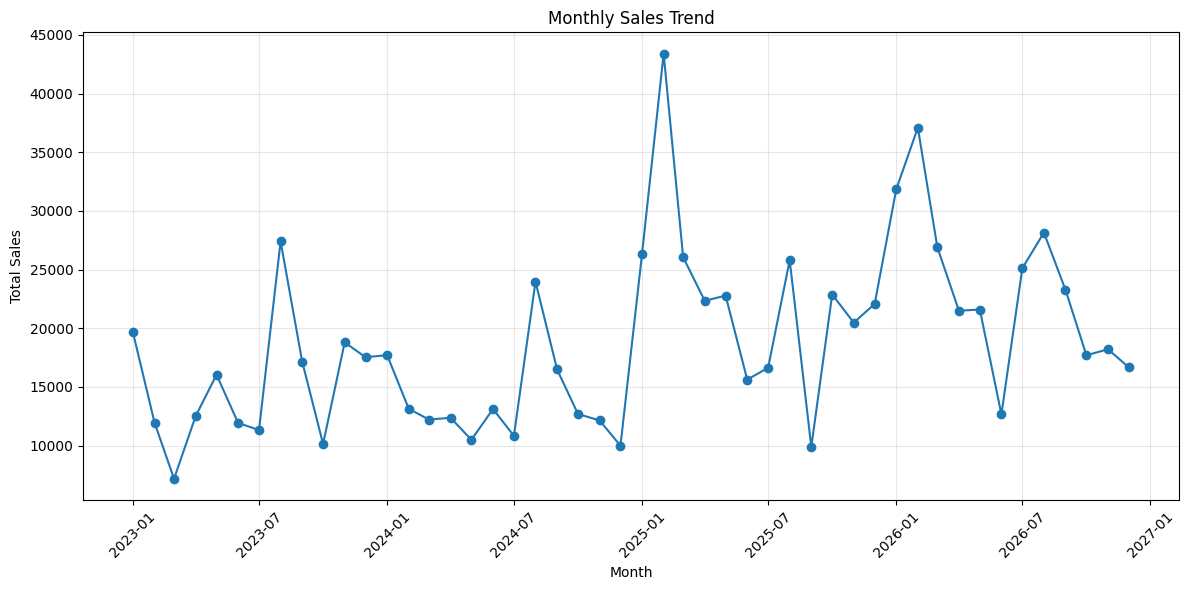

In [8]:

plt.figure(figsize=(12, 6))

plt.plot(
    result['Month'],
    result['Total Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

result.to_csv(
    '/content/prepared_sales_timeseries.csv',
    index=False
)

plt.figure(figsize=(12, 6))
plt.plot(
    result['Month'],
    result['Total Sales'],
    marker='o'
)
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/sales_trend.png', dpi=300)
plt.close()

print("Both deliverables created successfully!")


Both deliverables created successfully!


In [10]:

from google.colab import files

files.download('/content/prepared_sales_timeseries.csv')
files.download('/content/sales_trend.png')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os

print(os.listdir('/content'))

['.config', 'prepared_sales_timeseries.csv', 'sales_trend.png', 'sample_-_superstore.csv', 'sample_data']


In [12]:
print(result.head(10))
print(result.info())
print(result.isnull().sum())
print(result.describe())

       Month  Total Sales
0 2023-01-01    19640.427
1 2023-02-01    11948.402
2 2023-03-01     7159.670
3 2023-04-01    12497.462
4 2023-05-01    16033.521
5 2023-06-01    11927.849
6 2023-07-01    11313.778
7 2023-08-01    27399.203
8 2023-09-01    17158.932
9 2023-10-01    10127.521
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Month        48 non-null     datetime64[ns]
 1   Total Sales  48 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 900.0 bytes
None
Month          0
Total Sales    0
dtype: int64
                     Month   Total Sales
count                   48     48.000000
mean   2024-12-15 17:00:00  18781.810825
min    2023-01-01 00:00:00   7159.670000
25%    2023-12-24 06:00:00  12464.451500
50%    2024-12-16 12:00:00  17607.948350
75%    2025-12-08 18:00:00  22973.082500
max    2026-1